# тема 1, домашнее задание

In [54]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {
          "cheap": "openai/gpt-4o-mini",
          #"cheap": "qwen/qwen-2.5-72b-instruct",
          "mid": "anthropic/claude-haiku-4.5",
          "strong": "anthropic/claude-sonnet-4.6"
          }
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}

TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

In [24]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [25]:
# контроль попыток: обёртка над запросами. Выход: грязный ответ модели в Json или ошибка
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")

In [26]:
# чат с моделью. Контроль температуры и tools, учёт токенов. Выход: чистый ответ модели
def chat(messages, model, tools=None, tag="chat", temperature=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [27]:
class Answer(BaseModel): # Базовый класс pydantic
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число или короткая фраза")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S) 
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [28]:
answer_schema=Answer # не экземпляр! схему содержит именно класс
SCHEMA_PROMPT.format(schema=json.dumps(answer_schema.model_json_schema(), ensure_ascii=False))

'Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{"properties": {"reasoning": {"description": "ход решения в два-три предложения", "title": "Reasoning", "type": "string"}, "final": {"description": "только итоговый ответ: число или короткая фраза", "title": "Final", "type": "string"}}, "required": ["reasoning", "final"], "title": "Answer", "type": "object"}'

In [29]:
# mini-loop. Попытки на получение внятного ответа с передачей неудачных ответов. Выход - поля из схемы: reasoninf, final
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [30]:
class Numeric(BaseModel):
    final: float = Field(description="ответ числом")

In [31]:
# реестр инструментов и функция их регистрации в формате OpenAI
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}



In [32]:
# калькулятор
OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod} # что это? объясни синтаксис и логику

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)): # ast.Constant - что это за проверка?
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body) # ast.parse что за метод?
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0") 
    except Exception as e:
        return f"ошибка вычисления: {e}"

register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")
json.dumps(TOOLS["calculator"]["schema"], ensure_ascii=False, indent=1)

'{\n "type": "function",\n "function": {\n  "name": "calculator",\n  "description": "Считает арифметическое выражение: числа, скобки, + - * / ** %",\n  "parameters": {\n   "properties": {\n    "expr": {\n     "description": "арифметическое выражение, например 17*23+5",\n     "title": "Expr",\n     "type": "string"\n    }\n   },\n   "required": [\n    "expr"\n   ],\n   "title": "CalcArgs",\n   "type": "object"\n  }\n }\n}'

In [33]:
SYSTEM = ("Ты решаешь задачи. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.")

# хранение трейсов
@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

# контроль повторов. seen - общий для всего шага
def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

# аварийный выход из цикла в случае повторов или максимума шагов
def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [34]:
# вызов инструмента. Возвращает сообщение с результатом для messages
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump()) # вызываем функцию и передаем ей аргумент: через model_dump() превращаем объект из pydantic-объекта в обычный Python-словарь для распаковки через ** в аргументы
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}


In [35]:
# основной цикл агента! на входе messages = промпт. На выходе - вся история
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]

In [36]:
# агент + замеры. Выход - трейсы
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [53]:
run = agent("Сколько будет 17 * 23 + 5? Посчитай инструментом.", MODELS["cheap"], ["calculator"])
show_trace(run)

user     | Сколько будет 17 * 23 + 5? Посчитай инструментом. 
assistant|  calculator{"expr": "17*23+5"}
tool     | 396 
assistant| FINAL: 396 
шагов: 2, цена: 0.239 ¢, время: 14.4 c


In [ ]:
# парсер вики
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}
# WIKI_HEADERS = {
#     "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
#     "Accept": "application/json, text/plain, */*",
#     "Accept-Language": "ru-RU,ru;q=0.9,en-US;q=0.8,en;q=0.7"
# }

def wiki(params, attempts=3):
    for attempt in range(attempts):
        r = requests.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")

class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")

class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

In [38]:
def web_search(query: str) -> str:
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 1})["search"]

    if not hits:
        return "No data"
    pages = wiki({"action":"query", "prop": "extracts", "explainttext": 1, "exinro": 1, "titles": hits[0]["title"]})["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    return f"[{hits[0]["title"]}] {text[:5000]}"

In [39]:
def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"


In [41]:
register(web_search, SearchArgs, "Ищет статью в англоязычной Википедии и возвращает её вступление")
register(python_exec, ExecArgs, "Выполняет код на Python в отдельном процессе и возвращает то, что он напечатал")

assert calculator("2+2") == "4"
assert calculator("2**10") == "1024"
assert "ошибка" in calculator("__import__('os')")
assert web_search("Scott Derrickson").startswith("[Scott Derrickson]")
assert web_search("qwxzv 1234567 nonsense") == "No data"
assert python_exec("print(sum(range(10)))") == "45"
assert "ZeroDivisionError" in python_exec("1/0")
assert "Код превысил 5 сек" in python_exec("import time; time.sleep(10)")
"инструменты работают"

'инструменты работают'

In [ ]:
class PageFindArgs(BaseModel):
    title: str = Field(description="точное название статьи Википедии, например '2026 in Japan'")
    keywords: str = Field(description="ключевые слова через запятую для поиска в тексте статьи")

def page_find(title: str, keywords: str) -> str:
    # Сначала проверяем, что статья существует (как в web_search)
    search_data = wiki({
        "action": "query",
        "list": "search",
        "srsearch": title,
        "srlimit": 1
    })
    hits = search_data.get("search", [])
    
    if not hits:
        return f"Статья '{title}' не найдена"
    
    # Используем точное название из поиска (как в web_search)
    actual_title = hits[0]["title"]
    
    # Получаем полный текст (без exintro, чтобы получить всю статью)
    pages_data = wiki({
        "action": "query",
        "prop": "extracts",
        "explaintext": 1,
        "titles": actual_title
    })
    pages = pages_data.get("pages", {})
    
    if not pages:
        return f"Статья '{title}' не найдена"
    
    text = next(iter(pages.values())).get("extract", "")
    if not text:
        return f"Статья '{title}' не найдена"
    
    # Поиск по ключевым словам с контекстом
    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    kw = [w.lower() for w in keywords.split() if w.strip()]
    
    if not kw:
        return f"Не переданы ключевые слова"
    
    hit_indices = {i for i, ln in enumerate(lines) if any(k in ln.lower() for k in kw)}
    if not hit_indices:
        return f"В статье '{actual_title}' не нашлось строк с ключевыми словами: {keywords}"
    
    # Расширяем контекст: по строке сверху и снизу
    context_indices = set()
    for i in hit_indices:
        for j in range(max(0, i - 1), min(len(lines), i + 2)):
            context_indices.add(j)
    
    sorted_idx = sorted(context_indices)
    chunks = []
    current_chunk = [sorted_idx[0]]
    for idx in sorted_idx[1:]:
        if idx == current_chunk[-1] + 1:
            current_chunk.append(idx)
        else:
            chunks.append("\n".join(lines[i] for i in current_chunk))
            current_chunk = [idx]
    chunks.append("\n".join(lines[i] for i in current_chunk))
    
    result = "\n---\n".join(chunks)
    return result[:5000]

register(page_find, PageFindArgs, "Читает полный текст статьи Википедии и возвращает только строки с ключевыми словами. Вызывайте после web_search, когда вступления недостаточно.")

In [57]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}

In [60]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    for task in tasks:
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": ok, "steps": run.steps, "tool_calls": sum(m["role"] == "tool" for m in run.messages),
                     "cost": run.cost, "seconds": round(run.seconds, 1), "answer": final_answer(run.answer)[:60], "gold": task["answer"]})
        (folder / f"{task['id']}.json").write_text(json.dumps({"task": task, "answer": run.answer, "correct": ok, "cost": run.cost,
                                                              "messages": run.messages}, ensure_ascii=False, indent=1), encoding="utf-8")
    return pd.DataFrame(rows)

def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    return fig

CONFIGS = {"без инструментов": [], "калькулятор": ["calculator"], "код": ["python_exec"], "поиск": ["web_search"],
           "безымянные": ["tool_a", "tool_b"]}

In [75]:
# Тесты для web_search
assert "Python" in web_search("Python programming language")
assert web_search("qwxzv1234567890nonsense") == "No data"
assert "No data" in web_search("") or len(web_search("")) > 0

# Тесты для page_find
# 1. Нормальный вход: статья есть, слово есть
assert "Python" in page_find("Python (programming language)", "Python")

# 2. Статья есть, но ключевых слов нет (исправили на "не нашлось")
assert "не нашлось" in page_find("Python (programming language)", "xyzzyxyzzy99999")

# 3. Несуществующая статья (функция вернёт "не найдена")
r = page_find("qwxzv1234567890nonexistent", "test")
assert "не найдена" in r or "ошибка" in r

print("Все тесты прошли!")

Все тесты прошли!


In [ ]:
# 1. датасет
with open("data/fresh.jsonl", "r", encoding="utf-8") as f:
    tasks = [json.loads(line) for line in f]

print(f"Загружено задач: {len(tasks)}")

# 2. Конфигурации инструментов
CONFIGS = {
    "без инструментов": [],
    "поиск": ["web_search"],
    "поиск+чтение": ["web_search", "page_find"],
}

# 3. Полный прогон 3x3
frames = []
for model_name, model_id in MODELS.items():
    for config_name, tool_names in CONFIGS.items():
        try:
            df = run_tasks(tasks, model_id, tool_names, config_name)
            frames.append(df)
            acc = df["correct"].mean()
            cost = df["cost"].sum()
        except Exception as e:
            print(f"Ошибка: {e}")

# 4. Собираем результаты
results = pd.concat(frames, ignore_index=True)
results.to_csv("results_raw.csv", index=False, encoding="utf-8")


Загружено задач: 41


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,41,0.00,0.00004,inf,1.00,2.1
1,поиск,gpt-4o-mini,41,0.27,0.00045,0.00167,3.93,18.7
2,поиск+чтение,gpt-4o-mini,41,0.51,0.00052,0.00102,4.32,20.8
3,без инструментов,claude-haiku-4.5,41,0.02,0.00082,0.03352,1.00,2.5
4,без инструментов,claude-sonnet-4.6,41,0.15,0.00206,0.01408,1.00,3.5
5,поиск,claude-haiku-4.5,41,0.39,0.00762,0.01952,3.34,17.2
6,поиск+чтение,claude-haiku-4.5,41,0.46,0.01166,0.02516,3.49,19.5
7,поиск+чтение,claude-sonnet-4.6,41,0.71,0.02541,0.03593,3.80,21.8
8,поиск,claude-sonnet-4.6,41,0.54,0.02819,0.05254,4.22,23.4


ImportError: `Import tabulate` failed.  Use pip or conda to install the tabulate package.

,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,без инструментов,gpt-4o-mini,41,0.00,0.00004,inf,1.00,2.1
1,поиск,gpt-4o-mini,41,0.27,0.00045,0.00167,3.93,18.7
2,поиск+чтение,gpt-4o-mini,41,0.51,0.00052,0.00102,4.32,20.8
3,без инструментов,claude-haiku-4.5,41,0.02,0.00082,0.03352,1.00,2.5
4,без инструментов,claude-sonnet-4.6,41,0.15,0.00206,0.01408,1.00,3.5
5,поиск,claude-haiku-4.5,41,0.39,0.00762,0.01952,3.34,17.2
6,поиск+чтение,claude-haiku-4.5,41,0.46,0.01166,0.02516,3.49,19.5
7,поиск+чтение,claude-sonnet-4.6,41,0.71,0.02541,0.03593,3.80,21.8
8,поиск,claude-sonnet-4.6,41,0.54,0.02819,0.05254,4.22,23.4


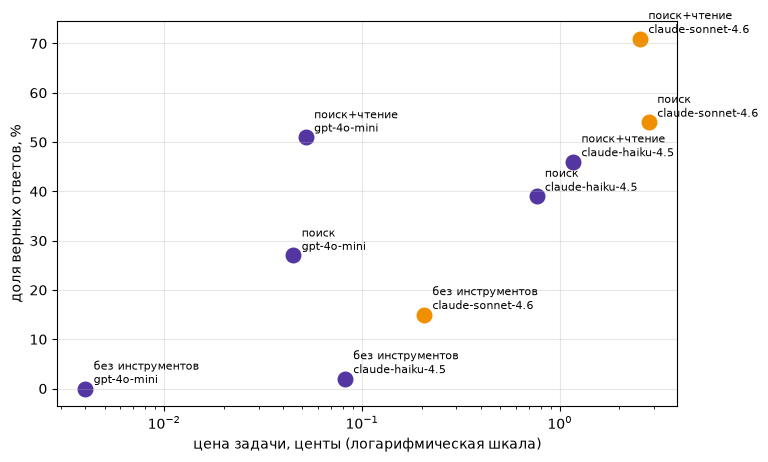

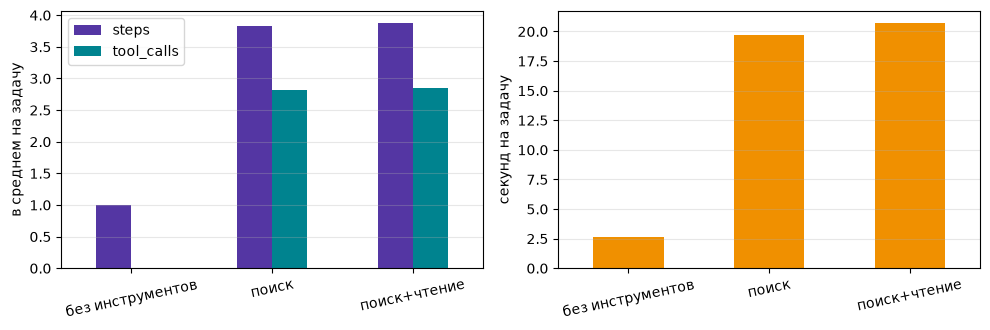

In [79]:
# 5. Свод
homework_table = report(results)
display(homework_table)

# 6. Графики
Path("img").mkdir(exist_ok=True)
fig1 = money_chart(homework_table, "img/money_quality.png")
fig2 = steps_chart(results)
